This is a quantitative skills and techniques demonstration.
We will showcase the following technical abilities:

1. Simulation of an SDE (price, IR).
2. Pricing of an option via montecarlo.
3. Pricing of an option via PDE.
4. Fitting an SDE to data via maximum likelihood.
5. Yield curve simulation.


In [3]:
# load relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simulation of an SDE
In this section we will implement the simulation of a

1. Geometric Brownian Motion.
2. Heston model.
3. Two factor Hull-White model.

NOTE: we will simulate discretized versions of continuous-time models (of course). They will be discretized according to the following global, unchanged, parameters:

In [4]:
N = 1000
dt = 0.01
T = N*dt

## Geometric Brownian Motion
A Geometric Brownian Motion (or GBM) is a stochastic process defined by the SDE 
$$dS(t) = \alpha(t)S(t)dt + \sigma(t)S(t)dW(t), $$
with initial condition $S(0) = S_0$. We will assume $\alpha$ and $\sigma$ to be constant.

The discretized version of this process is defined by the recursive relationship
$$ S(t+\Delta t) = S(t) + \alpha S(t) \Delta t + \sigma S(t) \sqrt{\Delta t} Z,$$
where $Z \sim N(0,1)$ is a standard normal random variable (that is sampled again and again for each $t$).

In [5]:
class GBM():
    def __init__(self, S_0, alpha, sigma):
        self.S_0 = S_0
        self.alpha = alpha
        self.sigma = sigma

    def simulate(self, M):

        S = np.full([N+1, M], self.S_0, dtype = np.dtype(float))
        Z = np.random.standard_normal([N,M])

        for i in range(N):
            S[i+1,:] = S[i,:]*(1 + self.alpha*dt + self.sigma*np.sqrt(dt)*Z[i,:])

        return S

    def simulate_and_plot(self, M=1000):
        simulation = self.simulate(M)
        pd.DataFrame(simulation).plot(legend=False)
        plt.show()

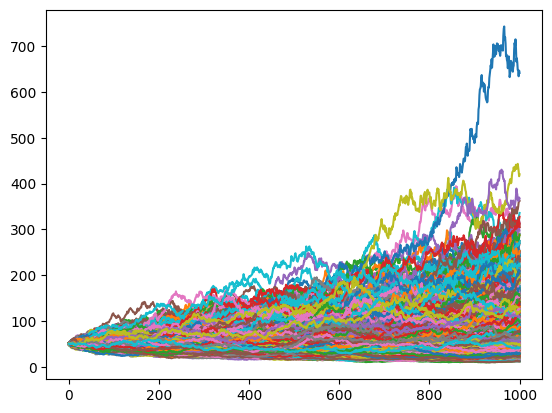

In [6]:
gbm = GBM(50, 0.05, 0.2)
gbm_sim = gbm.simulate_and_plot(1000)

## Heston Model
The Heston model is a stochastic volatility model defined by

$$\begin{cases}
dS(t) &= \mu S(t)dt + \sqrt{\nu(t)}S(t)dW_S(t)\\
d\nu(t) &= \kappa(\theta - \nu(t))dt + \xi\sqrt{\nu(t)}dW_\nu(t)\\
dS(t)d\nu(t) &= \rho dt
\end{cases}$$

If the Feller condition $2\kappa\theta > \xi^2$ holds, then $\nu(t)$ is strictly positive.

Discretized, this is
$$\begin{cases}
S(t+\Delta t) &= S(t) + \mu S(t)\Delta t + \sqrt{\nu(t)}S(t)\sqrt{\Delta t}Z_S\\
\nu(t+\Delta t) &= \nu(t) + \kappa(\theta - \nu(t))\Delta t + \xi \sqrt{\nu(t)}\sqrt{\Delta t} Z_\nu,
\end{cases}$$
where the correlation between $Z_S$ and $Z_\nu$ (which are sampled for each $t$), is $\rho$.

In [7]:
class Heston():
    def __init__(self,
                 S_0,
                 mu,
                 nu_0,
                 kappa,
                 theta,
                 xi,
                 rho):
        self.S_0 = S_0
        self.mu = mu
        self.nu_0 = nu_0
        self.kappa = kappa
        self.theta = theta
        self.xi = xi
        self.rho = rho

    def simulate(self, M):
        if 2*self.kappa*self.theta <= self.xi**2:
            print("ERROR: Feller condition not met, aborting simulation")
            return None, None
        
        C = np.array([[1, self.rho],[self.rho,1]])
        Z = np.random.multivariate_normal(np.zeros(2), C, (N,M))
        S  = np.full([N+1, M], self.S_0,  dtype=np.dtype(float))
        nu = np.full([N+1, M], self.nu_0, dtype=np.dtype(float))

        for i in range(N):
            S[i+1,:] = S[i,:]*(1 + self.mu*dt + np.sqrt(nu[i,:]*dt)*Z[i,:,0])
            nu[i+1,:] = np.maximum(nu[i,:] + self.kappa*(self.theta-nu[i,:])*dt + self.xi*np.sqrt(nu[i,:]*dt)*Z[i,:,1],
                                   0)

        return S, nu

    def simulate_and_plot(self, M=1000):
        S, nu = self.simulate(M)
        if S is None and nu is None:
            return

        fig, axes = plt.subplots(1,2, figsize=(12,5))
        axes[0].set_title("Price")
        pd.DataFrame(S).plot(legend=False, ax=axes[0])
        axes[1].set_title("Volatility")
        pd.DataFrame(nu).plot(legend=False, ax=axes[1])
        plt.show()


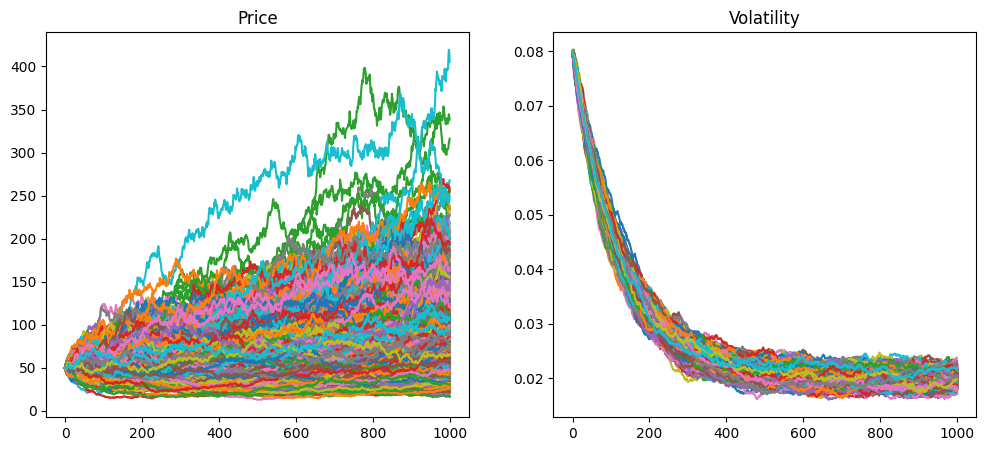

In [8]:
S_0 = 50
mu = 0.05
nu_0 = 0.08
kappa = 0.8
theta = 0.02
xi = 0.01
rho = 0.3
heston = Heston(S_0, mu, nu_0, kappa, theta, xi, rho)
heston_sim = heston.simulate_and_plot()


## Two factor Hull-White model
In contrast to our previous simulations, this model is often used to represent interest rates. It is defined by
$$\begin{cases}
dR(t) &= (\theta+u(t)-\alpha R(t))dt + \sigma_1 dW_1(t)\\
du(t) &= -bu(t)dt + \sigma_2 dW_2(t)\\
dW_1(t)dW_2(t)&=\rho dt
\end{cases}$$

Discretizing, we obtain
$$\begin{cases}
R(t+\Delta t) &= R(t)+ (\theta+u(t)-\alpha R(t))\Delta t + \sigma_1 \sqrt{\Delta t}Z_1\\
u(t+ \Delta t) &= u(t) -bu(t)\Delta t + \sigma_2 \sqrt{\Delta t}Z_2,\\
\end{cases}$$
where $Z_1$ and $Z_2$ are standard normal random variables with correlation $\rho$.

In [9]:
class HW2F():
    def __init__(self,
                 R_0,
                 theta,
                 alpha,
                 sigma_1,
                 u_0,
                 b,
                 sigma_2,
                 rho):
        self.R_0 = R_0
        self.theta = theta
        self.alpha = alpha
        self.sigma_1 = sigma_1
        self.u_0 = u_0
        self.b = b
        self.sigma_2 = sigma_2
        self.rho = rho

    def simulate(self, M):
        
        C = np.array([[1, self.rho],[self.rho,1]])
        Z = np.random.multivariate_normal(np.zeros(2), C, (N,M))
        R  = np.full([N+1, M], self.R_0,  dtype=np.dtype(float))
        u = np.full([N+1, M], self.u_0, dtype=np.dtype(float))

        for i in range(N):
            R[i+1,:] = R[i,:] + (self.theta + u[i,:]-self.alpha*R[i,:])*dt+self.sigma_1*np.sqrt(dt)*Z[i,:,0]
            u[i+1,:] = u[i,:]*(1-self.b*dt) + self.sigma_2*np.sqrt(dt)*Z[i,:,1]       

        return R, u

    def simulate_and_plot(self, M=1000):
        R, u = self.simulate(M)
        if R is None and u is None:
            return

        fig, axes = plt.subplots(1,2, figsize=(12,5))
        axes[0].set_title("Interest Rate")
        pd.DataFrame(R).plot(legend=False, ax=axes[0])
        axes[1].set_title("Perturbation")
        pd.DataFrame(u).plot(legend=False, ax=axes[1])
        plt.show()

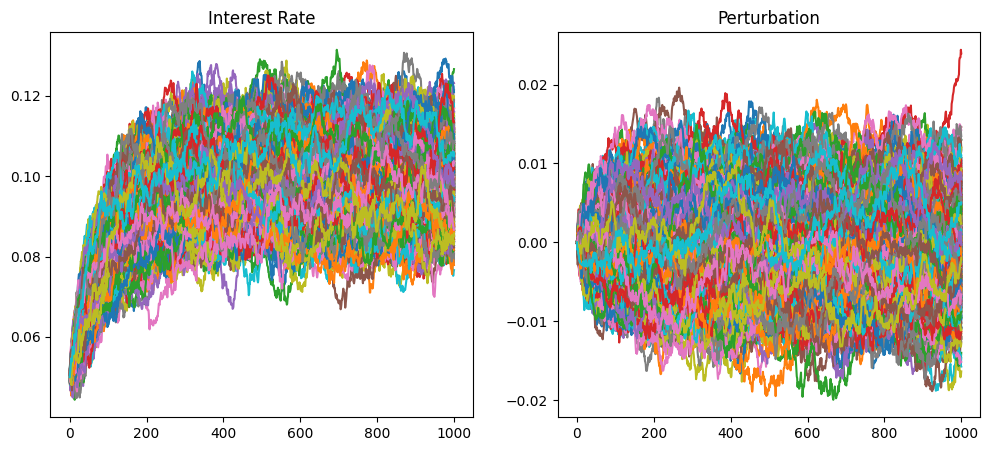

In [10]:
R_0 = 0.05
theta = 0.1
alpha = 1
sigma_1 = 0.01
u_0 = 0
b = 0.5
sigma_2 = 0.005
rho = -0.25
hw2f = HW2F(R_0, theta, alpha, sigma_1, u_0, b, sigma_2, rho)
hw2f.simulate_and_plot()

# Option Pricing via Monte Carlo
According to Steven Shreve's Stochastic Calcululs for finance, if $D(t) = \exp(-\int_0^tR(t)dt)$ is the discount process, then the price of an option at time $t$ that pays $V(T)$ at time $T$ is
$$V(t) = \mathbb{E}\left[e^{-\int_t^TR(t)dt}V(T)|\mathcal{F}(t)\right]$$

We will price a call option: that is, a derivative that pays $V(T) = (S(T)-K)^+$ at time $T$. By writing this conditional expecation in terms of a $\mathcal{F}(t)$-measurable random variable and random variable independent of $\mathcal{F}(t)$, we can compute this conditional expectation as a regular expectation using the Independence Lemma.

## Geometric Brownian Motion with constant interest rate
In this case and the next we assume constant interest rate, so that $V(t) = e^{-r(T-t)}\mathbb{E}[(S(T)-K)^+]$. We will assume $r = 0.1$. 

In [11]:
def price_call_option(prices, K, r, t=0):
    if type(r) == float:
        return np.exp(-r*(T-t))*np.mean(np.maximum(prices[-1,:]-K, 0))

    D = np.exp(-dt*np.sum(r, axis=0))
    return np.dot(D, np.maximum(prices[-1,:]-K, 0))/len(D)

In [12]:
r = 0.05

alpha = 0.05
sigma = 0.02
S_0 = 50
K = 60
gbm = GBM(S_0, alpha, sigma)
prices = gbm.simulate(10000)
print("Price of a single call option using GBM: {:.4f}.".format(price_call_option(prices, K, r)))

Price of a single call option using GBM: 13.6292.


## Heston with constant interest rate
The theory is the same since again we assume constant interest rate.

In [13]:
r = 0.05

S_0 = 50
mu = 0.05
nu_0 = 0.08
kappa = 0.8
theta = 0.02
xi = 0.01
rho = 0.3
heston = Heston(S_0, mu, nu_0, kappa, theta, xi, rho)
prices = heston.simulate(10000)[0]
print("Price of a single call option using Heston: {:.4f}.".format(price_call_option(prices, K, r)))

Price of a single call option using Heston: 16.9469.


## Geometric Brownian Motion with stochastic interest rate
The prices we have just computed could be computed with exact formulas. So we will try something more complicated: princing a call option when interest rate follows a two factor Hull-WHite model and the price follows a GBM.

In [14]:
alpha = 0.05
sigma = 0.02
S_0 = 50
K = 60
gbm = GBM(S_0, alpha, sigma)
prices = gbm.simulate(10000)

R_0 = 0.05
theta = 0.1
alpha = 1
sigma_1 = 0.01
u_0 = 0
b = 0.5
sigma_2 = 0.005
rho = -0.25
hw2f = HW2F(R_0, theta, alpha, sigma_1, u_0, b, sigma_2, rho)
rates,u = hw2f.simulate(10000)

print("Price of a single call option using GBM and HW: {:.4f}.".format(price_call_option(prices, K, rates)))

Price of a single call option using GBM and HW: 8.6941.


## Conclusion
We have simulated two scenarios in which interest rates are constant. In this two scenarios, both prices had the same tendency to go up, so we ended up paying more for the one that had more uncertainty.

In the other case, where interest rate was lower in the beginning but later approaching the interest rate of the two first scenarios, we got a price for the call that was lower. This signals that by using a more realistic approach (that is, more complex), we have a different price, and that may mean an opportunity in the market.

NOTE: in the above computations we have assumed that the randomness in the rates and in the prices are independent. This is not necessarily realistic. Also, we have not used necessarily equivalent parameters, the computations are only for demonstration purposes

# Option pricing via Partial Differential Equations
We will solve the correspondent PDE by implementing a finite difference method. For this, we follow Chapter 5 in Peter J. Olver's *Introduction to Partial Differential Equations*.


## Price of a call option with GBM underlying
We will derive the equation for the evolution of a price call by computing the value of a discounted portfolio process to a discounted function process.
The Black-Scholes-Merton PDE is defined for $t\in [0,T)$ and $x\geq 0$ by the equation
$$c_t(t,x) +rxc_x(t,x)+\frac{1}{2}\sigma^2x^2c_{xx}(t,x) = rc(t,x),$$
with terminal condition $c(T,x) = (x-K)^+$ and boundary conditions $c(t,0)=0$ and $\lim_{x\to \infty}[c(t,x)-(x-e^{-r(T-t)}K)]=0$.
In order to implement a numerical scheme, we substitute partial derivatives by approximations. First, we construct the following lattice. Let $j\in \{0,...,J\}$ and $m \in \{0,...,M\}$. Then we fix $\Delta t$ and $\Delta x$ and define
$$t_j = j \Delta t, \quad x_m = m\Delta x$$
We have defined a latice on the square defined by $(J\Delta t, M\Delta x)$ and the origin. Next define $c_{j,m} = c(t_j,x_m)$ and approximate the partial derivatives by

$$\begin{cases}
\frac{\partial c}{\partial t}(t_j,x_m) &= \frac{c_{j,m}-c_{j-1,m}}{\Delta t} + O(\Delta t) \\
\frac{\partial c}{\partial x}(t_j,x_m) &= \frac{c_{j,m+1}-c_{j,m}}{\Delta x} + O(\Delta x) \\
\frac{\partial^2c}{\partial x^2}(t_j,x_m) &= \frac{c_{j,m+1}-2c_{j,m} + c_{j,m-1}}{(\Delta x)^2} + O((\Delta x)^2)
\end{cases}$$

The general recurrent relationship this PDE implies is the following:

$$\begin{cases}
c_{j-1,m}&= \Deltat\left(-r\frac{1}{\Delta t} -\frac{
\end{cases}$$

In [21]:
class Lattice():
    def __init__(self,
                 dt,
                 J,
                 dx,
                 M,
                 x_0 = 0,
                 t_0 = 0):
        self.dt = dt
        self.J = J
        self.dx = dx
        self.M = M
        self.x_0 = x_0
        self.t_0 = t_0

    def get_value(self, j, m):
        return np.array([self.t_0+j*self.dt, self.x_0+m*self.dx])

    def get_x_M(self):
        return self.x_0 + self.M*self.dx

    def get_t_J(self):
        return self.t_0 + self.J*self.dt

class BSM_solver():
    def __init__(self, lattice, gbm, r, K):
        self.lattice = lattice
        self.gbm = gbm
        self.r = r
        self.K = K

    def solve_for_lattice(self):
        c = np.zeros([self.lattice.J+1, self.lattice.M+1])

        x_M, t_J = self.lattice.get_x_M(), self.lattice.get_t_J()
        for t in range(self.lattice.J+1):
            c[t,self.lattice.M] = np.maximum(x_M - np.exp(-self.r*(t_J-t))*self.K, 0)
        for m in range(self.lattice.M+1):
            x = self.lattice.get_value(self.lattice.J, m)[1]
            c[self.lattice.J, m] = np.maximum(x-self.K, 0)
        
        

        def compute_matrix():
            size = self.lattice.M
            vam1, vap1 = np.zeros(size), np.zeros(size)
            va = np.zeros(size)

            x = np.array(self.lattice.get_value(0,m)[1] for m in range(self.lattice.M))
            for m in range(1, size):
                x = self.lattice.get_value(0,m)[1]
                fraction2 = 0.5*(self.gbm.sigma*x/self.lattice.dx)**2
                vam1[m] = fraction2*self.lattice.dt
                va[m] = 1+self.lattice.dt*(-r-r*x/self.lattice.dx - fraction2)
                vap1[m] = self.lattice.dt*(r*x/self.lattice.dx + fraction2)

            return vam1, va, vap1 
        
        def multiply_tridiagonal(A, v):
            u = np.zeros(len(v))
            for m in range(1, self.lattice.M):
                u[m] = A[0][m] * v[m-1] + A[1][m]*v[m] + A[2][m]*v[m+1]
            return u

        A = compute_matrix()
        for i in range(0, self.lattice.J):
            t = self.lattice.J - i - 1
            c[t, :] = multiply_tridiagonal(A, c[t+1,:])

        return c

        

In [36]:
Dt =  1e-4
J = int(T/Dt)
dx = 1.1
X_min = 0
X_max = 200
M = int((X_max-X_min)/dx)
lattice = Lattice(Dt, J, dx, M, x_0=50)

alpha = 0.05
sigma = 0.02
S_0 = 50
gbm = GBM(S_0, alpha, sigma)

K = 60
r = 0.05
BS = BSM_solver(lattice, gbm, r, K)

c = BS.solve_for_lattice()
c[0,S_0]

/tmp/ipykernel_5140/2134343851.py:37: RuntimeWarning: overflow encountered in scalar multiply
  c[t,self.lattice.M] = np.maximum(x_M - np.exp(-self.r*(t_J-t))*self.K, 0)
/tmp/ipykernel_5140/2134343851.py:37: RuntimeWarning: overflow encountered in exp
  c[t,self.lattice.M] = np.maximum(x_M - np.exp(-self.r*(t_J-t))*self.K, 0)


np.float64(6.155167072924462e+20)

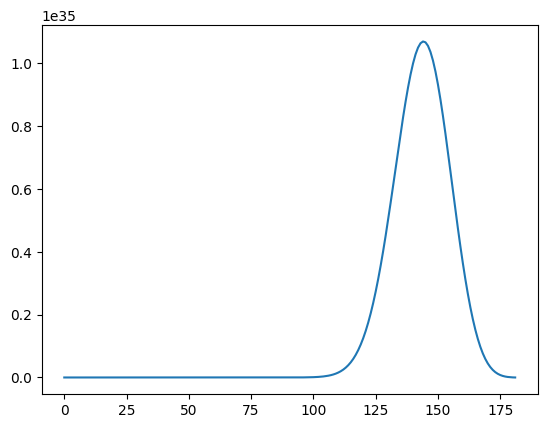

In [37]:
plt.plot(c[0,:])